# Günəş paneli, optik qat, linza və CPV: təkrarlana bilən mühəndislik modeli (v2)

Bu notebook `solarsim` paketini işlədir. Eyni paket CLI-də (`python -m solarsim.build`) və saytın məlumat dəstlərində də işlənir,
ona görə notebook, brauzer və cədvəllərdəki rəqəmlər eyni hesabdan gəlir. Brauzerdəki JS hesabı Python ilə paritet testləri ilə yoxlanır.

**Sual.** Eyni işıqtoplama sahəsində (apertura) linzalı və linzasız qurğular il ərzində nə qədər xalis DC enerji verir?
Linzanın qazanc və ya itki verməsi əvvəlcədən qəbul edilmir: modelin girişləri və yoxlamaları bunu müəyyən edir.

| Bölmə | Məzmun |
|---|---|
| 1 | Reqressiya bazası: v1 nəticələrinin təkrarlanması |
| 2 | Məlumat dəstləri: PVGIS 5.3 və PVGIS 6, üç məkan, vaxt və ofset yoxlaması |
| 3 | Modul: parametrlərin statusu, STC, NOCT və kalibrləmə üsulu |
| 4 | Ssenarilər: brüt, köməkçi sərf və xalis enerji, aylar, hava sinifləri |
| 5 | İllərarası dəyişkənlik (2005–2023) |
| 6 | Linza: sonlu həndəsə, işıq balansı, I–V modeli, şüa izləməsi |
| 7 | CPV və C = 5 sınağı |
| 8 | Çıxış faylları |
| 9 | Nəticələr, fərziyyələr və prototip planı |

In [1]:
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
from IPython.display import Markdown, display

import solarsim
from solarsim import analysis as AN, geometry as G, lenslab as LL, optics as O, pv as PV
from solarsim import scenarios as S, studies as ST, weather as W
from solarsim.sites import PRESETS

ROOT = Path.cwd()
RES = ROOT / "results"; FIG = RES / "figures"; DATA = ROOT / "docs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("Python", platform.python_version(), "| pvlib", pvlib.__version__, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| solarsim", solarsim.MODEL_VERSION)

Python 3.12.10 | pvlib 0.16.1 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2 | solarsim 2.0.0


## 1. Reqressiya bazası
Əvvəlki modelin (v1, commit `ad549b0`) nəticələri `tests/baseline_v1.json` faylında saxlanılıb. v2 kodu v1 fərziyyələri ilə işlədildikdə
bu nəticələri 0,0001 kWh/m² dəqiqliklə təkrarlamalıdır. v2-nin standart parametrlərində yalnız CPV dəyişir: qəbul konusundakı
səpələnmiş işıq (DHI·sin²1°) və izləmə xətası (σ = 0,1°) əlavə olunub.

In [2]:
base_v1 = json.loads((ROOT / "tests" / "baseline_v1.json").read_text(encoding="utf-8"))
baku = W.pvgis53_tmy("baku")
r_v1mode = S.run(baku, S.override(S.default_params(), {("cpv", "diffuse_in_acceptance"): False}))
r_v2 = S.run(baku)
reg = pd.DataFrame({k: {"v1 brüt": base_v1["annual"][k]["gross_kWh_m2"], "v2 (v1 rejimi) brüt": r_v1mode.annual.loc[k, "gross_kWh_m2_ap"],
                        "v2 brüt": r_v2.annual.loc[k, "gross_kWh_m2_ap"], "v1 xalis": base_v1["annual"][k]["net_kWh_m2"],
                        "v2 (v1 rejimi) xalis": r_v1mode.annual.loc[k, "net_kWh_m2_ap"], "v2 xalis": r_v2.annual.loc[k, "net_kWh_m2_ap"]}
                    for k in S.SCEN}).T
for k in S.SCEN:
    assert abs(reg.loc[k, "v1 brüt"] - reg.loc[k, "v2 (v1 rejimi) brüt"]) < 1e-4
    assert abs(reg.loc[k, "v1 xalis"] - reg.loc[k, "v2 (v1 rejimi) xalis"]) < 1e-4
display(reg.round(4))
print("İzləmə + idarəetmə sərfi (v1 rejimi):", round(r_v1mode.annual.loc["A_2axis", "aux_kWh_unit"], 3), "kWh/qurğu/il",
      "= izləmə", round(r_v1mode.annual.loc["A_2axis", "drive_kWh_unit"], 3), "+ idarəetmə", round(r_v1mode.annual.loc["A_2axis", "controller_kWh_unit"], 3))
print("Qeyd: A-izləmənin 448,01 dəyəri brüt, 436,92 isə xalisdir.")

,v1 brüt,v2 (v1 rejimi) brüt,v2 brüt,v1 xalis,v2 (v1 rejimi) xalis,v2 xalis
A_fixed,355.4006,355.4006,355.4006,355.4006,355.4006,355.4006
B_fixed,310.7364,310.7364,310.7364,310.7364,310.7364,310.7364
A_2axis,448.0135,448.0135,448.0135,436.9210,436.9210,436.9210
C_2axis,314.7325,314.7325,314.7801,303.6400,303.6400,303.6876


İzləmə + idarəetmə sərfi (v1 rejimi): 22.164 kWh/qurğu/il = izləmə 17.784 + idarəetmə 4.38
Qeyd: A-izləmənin 448,01 dəyəri brüt, 436,92 isə xalisdir.


## 2. Məlumat dəstləri

* **PVGIS 5.3 TMY** (`re.jrc.ec.europa.eu/api/v5_3/tmy`): SARAH3 + ERA5, 2005–2023. Vaxt nişanları `HH:00` UTC-dir.
  Şüalanmanın vaxt ofseti cavabın `irradiance_time_offset` sahəsindən götürülür və günəş mövqeyinə **bir dəfə** tətbiq olunur.
* **PVGIS 5.3 saatlıq sıra** (`seriescalc`, 2005–2023): vaxt nişanında dəqiqələr var (Bakı `HH:10`, Naxçıvan və Almería `HH:09`).
  Ofset yenidən əlavə edilmir.
* **PVGIS 6 TMY** (`photovoltaic-geographic-information-system.ec.europa.eu/api/v6/meteorological/typical-meteorological-year`):
  API sənədlərinə görə “aktiv inkişaf mərhələsindədir”. Cavab DHI vermir və ay birləşmələrində gecə dəyərləri var. Təmizləmə qaydası metadatada saxlanılır.

**40° E-dən şərqdə SARAH vaxt nişanları üzrə yoxlama.** JRC sənədlərində (PVGIS 5.x API səhifəsi və PVGIS 6 sənədləri, 2026-11-08) belə bir düzəliş təsvir olunmayıb.
Ona görə bunu məlumatın özündə yoxladıq. Bakı (49,87° E) və Naxçıvan (45,41° E) üçün ofset 0,1672 və 0,1661 saatdır, Almería (−2,46° E) üçün 0,1657 saat.
Saatlıq sırada PVGIS-in öz `H_sun` dəyəri pvlib SPA ilə vaxt nişanının özündə 0,14° fərqlə üst-üstə düşür. Ofset ikinci dəfə əlavə edilsə, fərq 1,35° olur.
Deməli, bu nöqtələrdə əlavə uzunluq düzəlişi müşahidə olunmur. Ofset mənbənin metadatasından bir dəfə tətbiq olunur.

In [3]:
ds_all = {}
for key in PRESETS:
    for src, loader in (("pvgis53", W.pvgis53_tmy), ("pvgis6", W.pvgis6_tmy)):
        ds_all[f"{key}_{src}_tmy"] = loader(key)
meta_tab = pd.DataFrame({k: {"məkan": d.site.name, "API": d.meta["api_version"].split(" ")[0], "radiasiya bazası": d.meta["radiation_db"][:28],
                             "illər": "–".join(map(str, d.meta["years"])), "sorğu (UTC)": d.meta["requested_utc"][:16],
                             "addım, saat": d.step_h, "ofset, saat": d.meta["solpos_offset_h"], "çatışmayan sətir": d.meta["completeness"]["n_missing"],
                             "GHI, kWh/m²": d.df["ghi"].sum() * d.step_h / 1000, "DNI, kWh/m²": d.df["dni"].sum() * d.step_h / 1000,
                             "DHI, kWh/m²": d.df["dhi"].sum() * d.step_h / 1000} for k, d in ds_all.items()}).T
display(meta_tab.round(3))
for k, d in ds_all.items():
    if d.meta["cleaning"]:
        print(k, "təmizləmə:", *d.meta["cleaning"], sep="\n  - ")

,məkan,API,radiasiya bazası,illər,sorğu (UTC),"addım, saat","ofset, saat",çatışmayan sətir,"GHI, kWh/m²","DNI, kWh/m²","DHI, kWh/m²"
baku_pvgis53_tmy,Bakı,5.3,PVGIS-SARAH3,2005–2023,2026-11-08T15:18,1.0,0.1672,0,1487.011,1315.34079,656.734
baku_pvgis6_tmy,Bakı,6,SARAH-3 / ERA5 (PVGIS 6 əhat,2015–2024,2026-11-08T15:18,1.0,0.1663,0,1537.492752,1361.263176,661.920443
naxcivan_pvgis53_tmy,Naxçıvan,5.3,PVGIS-SARAH3,2005–2023,2026-11-08T15:18,1.0,0.1661,0,1748.083,1755.08325,635.986
naxcivan_pvgis6_tmy,Naxçıvan,6,SARAH-3 / ERA5 (PVGIS 6 əhat,2014–2024,2026-11-08T15:19,1.0,0.1663,0,1744.647947,1799.993813,624.102368
almeria_pvgis53_tmy,Almería,5.3,PVGIS-SARAH3,2005–2023,2026-11-08T15:19,1.0,0.1657,0,1881.551,2234.55725,563.53
almeria_pvgis6_tmy,Almería,6,SARAH-3 / ERA5 (PVGIS 6 əhat,2014–2024,2026-11-08T15:19,1.0,0.1663,0,1891.868462,2205.079234,589.204837


baku_pvgis6_tmy
  - təmizləmə:
  - Boş (NaN) qiymətlər (GHI 13, DNI 12, temperatur 0, külək 0) xətti interpolyasiya ilə dolduruldu (≤ 3 saat); 0 qiymət 0 götürüldü
  - Günəş üfüqün altında olduğu halda GHI/DNI > 0 olan 73 gecə sətri 0 götürüldü (TMY ayları birləşən yerlərdə xətti keçidlər)
  - DHI = GHI − DNI·cos(z) kimi hesablandı (API vermir); DNI·cos(z) GHI-dən böyük olan 2 sətirdə DNI azaldıldı
naxcivan_pvgis6_tmy
  - təmizləmə:
  - Boş (NaN) qiymətlər (GHI 17, DNI 11, temperatur 0, külək 0) xətti interpolyasiya ilə dolduruldu (≤ 3 saat); 0 qiymət 0 götürüldü
  - Günəş üfüqün altında olduğu halda GHI/DNI > 0 olan 81 gecə sətri 0 götürüldü (TMY ayları birləşən yerlərdə xətti keçidlər)
  - DHI = GHI − DNI·cos(z) kimi hesablandı (API vermir); DNI·cos(z) GHI-dən böyük olan 3 sətirdə DNI azaldıldı
almeria_pvgis6_tmy
  - təmizləmə:
  - Boş (NaN) qiymətlər (GHI 25, DNI 13, temperatur 0, külək 0) xətti interpolyasiya ilə dolduruldu (≤ 3 saat); 0 qiymət 0 götürüldü
  - Günəş üfüqün altında 

In [4]:
# timing test: PVGIS sun height vs pvlib SPA for hourly series (offset must not be applied twice)
for key in PRESETS:
    y = W.pvgis53_series(key)[2020]
    hs = y.meta["h_sun_pvgis_deg"]; m = hs > 5
    for shift in (0.0, y.meta.get("label_minute", 0) / 60):
        sp = G.solar_position(W.Dataset(y.id, y.site, y.df, {**y.meta, "solpos_offset_h": shift}))
        print(f"{key}: vaxt nişanı +{shift:.3f} saat → orta |H_sun − SPA| = {np.mean(np.abs(hs[m] - sp['elevation'].to_numpy()[m])):.3f}°")

baku: vaxt nişanı +0.000 saat → orta |H_sun − SPA| = 0.138°
baku: vaxt nişanı +0.167 saat → orta |H_sun − SPA| = 1.354°


naxcivan: vaxt nişanı +0.000 saat → orta |H_sun − SPA| = 0.186°
naxcivan: vaxt nişanı +0.150 saat → orta |H_sun − SPA| = 1.117°


almeria: vaxt nişanı +0.000 saat → orta |H_sun − SPA| = 0.201°
almeria: vaxt nişanı +0.150 saat → orta |H_sun − SPA| = 1.172°


## 3. Modul: parametrlər, STC, NOCT
Parametrlərin statusu: **pasport** — rəsmi texniki pasport (TSM_EN_2023_B), **ölçülüb** — ölçü ilə təsdiqlənib (hələ yoxdur),
**fərziyyə** — qəbul edilmiş dəyər. NOCT-a kalibrləmə pasporta uyğunlaşdırmadır, ölçü deyil, ona görə status dəyişmir.

In [5]:
m = PV.Module()
display(pd.DataFrame([{"parametr": k, "dəyər": p.value, "vahid": p.unit, "status": p.status, "qeyd": p.note} for k, p in m.p.items()]))
print(f"STC: {PV.pvwatts(1000, 25, m.v('pdc0_W'), m.v('gamma_pdc')):.3f} W; modul səthinə görə səmərəlilik {m.eta_stc * 100:.2f}%")
n = PV.noct_check(m)
print(f"NOCT: SAPM {n['t_cell_model_C']:.2f} °C, pasport {n['t_noct_datasheet_C']:.0f} ± 2 °C (fərq {n['dT_C']:+.2f} K); "
      f"güc {n['p_model_W']:.1f} W, pasport {n['p_noct_datasheet_W']:.0f} W")
a_cal = PV.calibrate_sapm_a_to_noct(m)
print(f"Kalibrləmə üsulu: SAPM a = {a_cal:.4f} (standart −3,47) seçiləndə NOCT şəraitində {PV.noct_check(m, a=a_cal)['t_cell_model_C']:.2f} °C alınır. "
      "Əsas hesab montaj tipinin elmi əmsalları ilə aparılır; ölçü olmadan status 'fərziyyə' qalır.")
print(f"Aktiv sahə payı {m.active_fraction:.2f} (fərziyyə) → hüceyrə 182 × {m.cell_h_mm:.2f} mm; sadə və həndəsi model eyni dəyəri işlədir.")

,parametr,dəyər,vahid,status,qeyd
0,pdc0_W,450.0,W,pasport,"STC: 1000 W/m², 25 °C, AM1,5; tolerans 0…+5 W"
1,length_mm,1762.0,mm,pasport,
2,width_mm,1134.0,mm,pasport,
3,n_cells,144,-,pasport,
4,gamma_pdc,-0.003,1/°C,pasport,−0.30 %/°C
5,beta_voc,-0.0024,1/°C,pasport,
6,alpha_isc,0.0004,1/°C,pasport,
7,vmpp_V,44.6,V,pasport,
8,impp_A,10.09,A,pasport,
9,voc_V,52.9,V,pasport,


STC: 450.000 W; modul səthinə görə səmərəlilik 22.52%
NOCT: SAPM 45.86 °C, pasport 43 ± 2 °C (fərq +2.86 K); güc 337.5 W, pasport 343 W
Kalibrləmə üsulu: SAPM a = -3.5999 (standart −3,47) seçiləndə NOCT şəraitində 43.00 °C alınır. Əsas hesab montaj tipinin elmi əmsalları ilə aparılır; ölçü olmadan status 'fərziyyə' qalır.
Aktiv sahə payı 0.92 (fərziyyə) → hüceyrə 182 × 70.14 mm; sadə və həndəsi model eyni dəyəri işlədir.


## 4. Ssenarilər: brüt, köməkçi sərf, xalis
Hər qurğu üçün brüt DC, köməkçi sərf (izləmə + idarəetmə + soyutma) və xalis enerji ayrıca hesablanır. Vahidlər:
W — ani güc, W/m² — şüalanma, kWh/qurğu/il — qurğunun enerjisi, kWh/m² apertura/il — işıqtoplama sahəsinə normallaşdırılmış enerji.
Torpaq sahəsi sıra məsafəsindən (GCR, fərziyyə) asılıdır və ayrıca verilir. Müqayisə cütləri: sabit A ↔ sabit B, iki oxlu A-izləmə ↔ iki oxlu C.

In [6]:
runs = {k: S.run(d) for k, d in ds_all.items()}
rows = []
for k, r in runs.items():
    for s in S.SCEN:
        a = r.annual.loc[s]
        rows.append({"dəst": k, "ssenari": s, "brüt kWh/qurğu": a.gross_kWh_unit, "izləmə": a.drive_kWh_unit, "idarəetmə": a.controller_kWh_unit,
                     "soyutma": a.cooling_kWh_unit, "xalis kWh/qurğu": a.net_kWh_unit, "brüt kWh/m² ap": a.gross_kWh_m2_ap,
                     "xalis kWh/m² ap": a.net_kWh_m2_ap, "xalis kWh/m² torpaq": a.net_kWh_m2_ground})
annual_all = pd.DataFrame(rows)
display(annual_all.round(2))
# consistency with the site datasets (same code, same inputs)
for k, r in runs.items():
    js = json.loads((DATA / f"{k}.json").read_text(encoding="utf-8"))
    for s in S.SCEN:
        assert abs(js["annual"][s]["net_kWh_unit"] - r.annual.loc[s, "net_kWh_unit"]) < 1e-6, (k, s)
print("Notebook = sayt məlumat dəstləri (bütün dəstlər, bütün ssenarilər): uyğundur")

,dəst,ssenari,brüt kWh/qurğu,izləmə,idarəetmə,soyutma,xalis kWh/qurğu,brüt kWh/m² ap,xalis kWh/m² ap,xalis kWh/m² torpaq
0,baku_pvgis53_tmy,A_fixed,710.13,0.00,0.00,0.0,710.13,355.40,355.40,142.16
1,baku_pvgis53_tmy,B_fixed,620.88,0.00,0.00,0.0,620.88,310.74,310.74,124.29
2,baku_pvgis53_tmy,A_2axis,895.18,17.78,4.38,0.0,873.02,448.01,436.92,109.23
3,baku_pvgis53_tmy,C_2axis,628.96,17.78,4.38,0.0,606.80,314.78,303.69,75.92
4,baku_pvgis6_tmy,A_fixed,720.39,0.00,0.00,0.0,720.39,360.54,360.54,144.21
5,baku_pvgis6_tmy,B_fixed,630.12,0.00,0.00,0.0,630.12,315.36,315.36,126.14
6,baku_pvgis6_tmy,A_2axis,914.43,17.79,4.38,0.0,892.26,457.65,446.55,111.64
7,baku_pvgis6_tmy,C_2axis,649.68,17.79,4.38,0.0,627.52,325.15,314.06,78.51
8,naxcivan_pvgis53_tmy,A_fixed,832.97,0.00,0.00,0.0,832.97,416.88,416.88,166.75
9,naxcivan_pvgis53_tmy,B_fixed,732.35,0.00,0.00,0.0,732.35,366.52,366.52,146.61


Notebook = sayt məlumat dəstləri (bütün dəstlər, bütün ssenarilər): uyğundur


,saat,A_fixed,B_fixed,A_2axis,C_2axis
clear,827.0,149.28,133.40,169.01,144.23
hazy,895.0,104.81,91.47,150.58,115.50
partly,1071.0,73.34,62.59,102.39,53.58
overcast,1169.0,27.70,23.06,25.86,1.47
low_light,4798.0,0.27,0.22,0.17,0.00
kd_above_1,0.0,0.00,0.00,0.00,0.00
cəm,8760.0,355.40,310.74,448.01,314.78


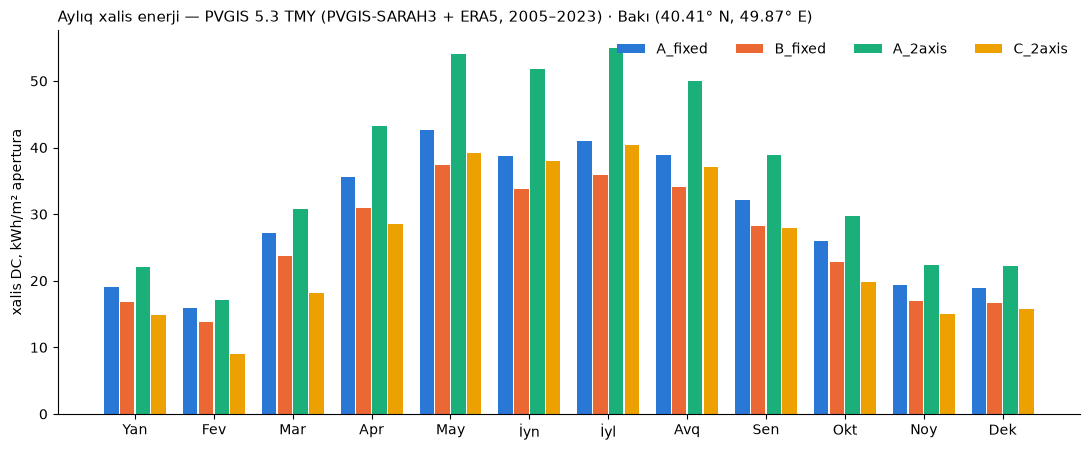

In [7]:
r = runs["baku_pvgis53_tmy"]; d = ds_all["baku_pvgis53_tmy"]; A = r.areas["aperture_m2"]
mon = pd.DataFrame({s: AN.monthly_kWh(d, r.hourly[s]["net_W"]) / A for s in S.SCEN})
for s in S.SCEN:
    assert abs(mon[s].sum() - r.annual.loc[s, "net_kWh_m2_ap"]) < 1e-9
sky = pd.DataFrame({s: AN.by_sky_class_kWh(d, r.hourly[s]["gross_W"])["kWh"] / A for s in S.SCEN})
sky.insert(0, "saat", AN.by_sky_class_kWh(d, r.hourly["A_fixed"]["gross_W"])["hours"])
sky.loc["cəm"] = sky.sum()
display(sky.round(2))
assert abs(sky.loc["cəm", "A_fixed"] - r.annual.loc["A_fixed", "gross_kWh_m2_ap"]) < 1e-9
colors = {"A_fixed": "#2a78d6", "B_fixed": "#eb6834", "A_2axis": "#1baf7a", "C_2axis": "#eda100"}
fig, ax = plt.subplots(figsize=(11, 4.6))
w = 0.2
for i, s in enumerate(S.SCEN):
    ax.bar(np.arange(12) + (i - 1.5) * w, mon[s].values, w * 0.92, color=colors[s], label=s)
ax.set_xticks(range(12), ["Yan", "Fev", "Mar", "Apr", "May", "İyn", "İyl", "Avq", "Sen", "Okt", "Noy", "Dek"])
ax.set_ylabel("xalis DC, kWh/m² apertura"); ax.legend(ncol=4, frameon=False)
ax.set_title(f"Aylıq xalis enerji — {d.label()}", loc="left", fontsize=11)
for sp_ in ("top", "right"): ax.spines[sp_].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "v2_monthly_net_baku.png", dpi=140); plt.show()

## 5. İllərarası dəyişkənlik
TMY tipik ildir. Konkret təqvim illərinin (PVGIS 5.3 saatlıq sırası, 2005–2023) nəticələri dəyişkənliyi göstərir.
Hesab `python -m solarsim.build` ilə aparılıb və məlumat dəstindən oxunur. Bakı üçün bir il burada yenidən hesablanır, nəticə dəstdəki ilə müqayisə olunur.

Bakı


,mean,std,min,max,"CV, %"
A_fixed,357.40,8.91,342.01,373.17,2.49
B_fixed,312.57,8.01,298.89,326.85,2.56
A_2axis,438.87,12.64,412.68,456.15,2.88
C_2axis,307.03,12.28,281.58,323.73,4.00


Naxçıvan


,mean,std,min,max,"CV, %"
A_fixed,411.27,11.06,393.34,431.29,2.69
B_fixed,361.70,10.00,345.43,379.92,2.76
A_2axis,517.98,14.89,495.00,545.77,2.88
C_2axis,405.80,14.94,382.50,435.38,3.68


Almería


,mean,std,min,max,"CV, %"
A_fixed,459.64,9.58,444.11,474.34,2.08
B_fixed,405.35,8.81,390.77,418.98,2.17
A_2axis,618.22,15.22,591.94,638.08,2.46
C_2axis,509.77,19.45,474.37,536.53,3.82


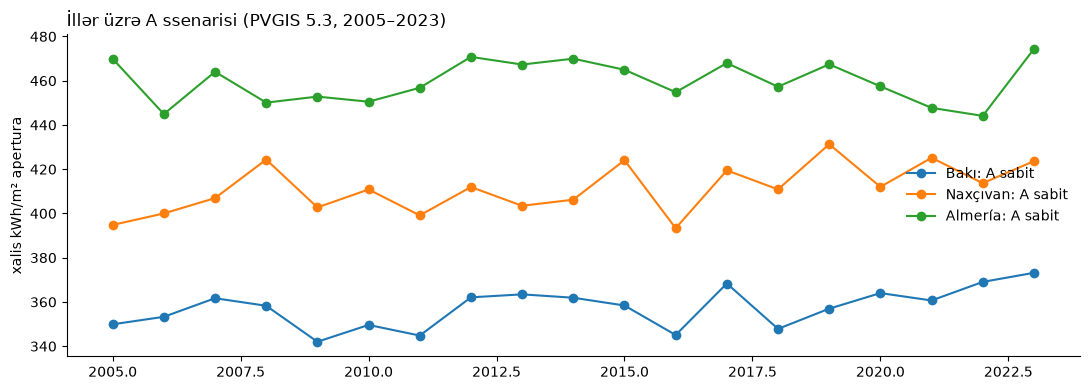

In [8]:
ia = {}
for key in PRESETS:
    js = json.loads((DATA / f"{key}_pvgis53_tmy.json").read_text(encoding="utf-8"))
    if "interannual" in js:
        t = pd.DataFrame(js["interannual"]["table"]).T.sort_index()
        ia[key] = t
        st = t[S.SCEN].agg(["mean", "std", "min", "max"]).T
        st["CV, %"] = 100 * st["std"] / st["mean"]
        print(PRESETS[key].name); display(st.round(2))
y2020 = S.run(W.pvgis53_series("baku")[2020]).annual.loc["A_fixed", "net_kWh_m2_ap"]
assert abs(y2020 - ia["baku"].loc["2020", "A_fixed"]) < 1e-6
fig, ax = plt.subplots(figsize=(11, 4))
for key, t in ia.items():
    ax.plot(t.index.astype(int), t["A_fixed"], marker="o", label=f"{PRESETS[key].name}: A sabit")
ax.set_ylabel("xalis kWh/m² apertura"); ax.legend(frameon=False); ax.set_title("İllər üzrə A ssenarisi (PVGIS 5.3, 2005–2023)", loc="left")
for sp_ in ("top", "right"): ax.spines[sp_].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "v2_interannual_A.png", dpi=140); plt.show()

## 6. Linza: sonlu həndəsə, işıq balansı, elektrik modeli, şüa izləməsi

**Sadə optik qat (B) və həndəsi laboratoriya modeli ayrı modellərdir.**
* Sadə modelin ideal ssenarisi **+7,84%**-dir. Şərtləri: aktiv sahə 92%, boşluq işığı tam qaytarılır, ötürmə 100%, əlavə istilik və qeyri-bərabərlik itkisi sıfır.
* Həndəsi model (`solarsim.optics`): nazik paraksial linza, sonlu panel. Spot öz hüceyrəyə, qonşu hüceyrəyə, boşluğa və paneldən kənara bölünür.
  Linza və modul şüşəsində əks olunma və udulma ayrıca hesablanır. Birbaşa, səma və yer işığı ayrı-ayrılıqda paylanır.
  Nəticə “boş linza”ya nisbətən diferensial üsulla pvlib baza ssenarisi A-ya tətbiq olunur.
* Etibarlılıq (`optics.validity`): f-ədədi N = |f| / a, kənar şüanın optik oxla bucağı θ = atan((a/2) / |f|). Hesab oxu: sferik linzada aperturası böyük olan ox, silindrik linzada yalnız maililik oxu y. Düzbucaqlı sferik linzanın künc şüası (diaqonal üzrə) ayrıca verilir.
  θ ≤ 10° yüksək, ≤ 20° orta, daha böyük aşağı etibarlılıqdır. 30° simulyatorun paraksial model üçün xəbərdarlıq meyarıdır, linzanın düzəldilə bilməsi haqqında hökm deyil.
  Aşağı etibarlılıqda fokus və enerji nəticəsi “kobud yaxınlaşdırma” sayılır. Axtarışın maksimumu bu zonadadırsa, etibarlı zonada ən yaxşı nəticə ayrıca verilir.

In [9]:
prep = LL.prepare(d)
null = LL.annual(prep, LL.NULL_LENS)
print(f"Boş linza zənciri pvlib A-dan {null['chain_vs_A_pct']:+.2f}% fərqlənir (diffuz nümunələmə və kənar həndəsə); diferensial üsul bu fərqi nəticəyə daxil etmir.")
js = json.loads((DATA / "baku_pvgis53_tmy.json").read_text(encoding="utf-8"))
tests = pd.DataFrame([{"D": t["P"], "düzülüş": t["mode"], **{k: v for k, v in t["points"].items()}, "ən yaxşı h, mm": t["best_h"],
                       "ən yaxşı, %": t["best_pct"], "ən yaxşı (I–V), %": t.get("best_iv"), "etibarlılıq": t["validity_best"]["reliability"]}
                      for t in js["lens"]["tests"]])
display(tests.round(2))
# recompute two table points here: must equal the dataset (same function)
for t in js["lens"]["tests"][:2]:
    r_ = LL.annual(prep, O.LensConfig(t["P"], 3.0, t["mode"], 0.92))
    assert abs(r_["delta_pct"] - t["points"]["şüşənin üstündə 3 mm"]) < 1e-9
for t in js["lens"]["tests"]:      # the reported optimum is never worse than a tested point
    for v in t["points"].values():
        assert t["best_pct"] >= v - 1e-9
for k in ("array", "array_cyl"):
    x = js["lens"][k]
    keep = lambda y: {kk: y[kk] for kk in ("P", "h", "delta_pct", "tau_breakeven")} | {"bucaq, °": round(y["validity"]["edge_angle_deg"], 1), "etibarlılıq": y["validity"]["reliability"]}
    if x["validity"]["coarse"]:
        print(f"{k}: axtarışın ümumi maksimumu — kobud yaxınlaşdırma, prototip seçimi deyil:", keep(x))
        if x.get("best_reliable"):
            print(f"{k}: etibarlı zonada ən yaxşı:", keep(x["best_reliable"]))
    else:
        print(f"{k}: sınanmış diapazonda ən yaxşı:", keep(x))
print("v1 nöqtəsi +13,5 D / 8 mm:", json.dumps(js["lens"]["v1_point_13p5D_8mm"], ensure_ascii=False)[:400])
display(pd.DataFrame(js["lens"]["iv_validation"]["rows"]).round(2))
display(pd.DataFrame([{"D": x["P"], "h": x["h"], "düzülüş": x["mode"], "bucaq": x["theta"],
                       "izləmə: hüceyrədə": (x["trace"].get("on_cells") if x["trace"]["traced"] else x["trace"]["note"]),
                       "paraksial": x["paraxial_y_on_cells"]} for x in js["lens"]["trace2d"]]))

Boş linza zənciri pvlib A-dan -0.61% fərqlənir (diffuz nümunələmə və kənar həndəsə); diferensial üsul bu fərqi nəticəyə daxil etmir.


,D,düzülüş,şüşənin üstündə 3 mm,10 sm sınaq məsafəsi,fokusda h = f,"ən yaxşı h, mm","ən yaxşı, %","ən yaxşı (I–V), %",etibarlılıq
0,3,array,-10.71,-43.50,-86.66,4.0,-10.62,-10.42,orta
1,3,array_cyl,-11.31,-47.09,-75.97,3.0,-11.31,-11.27,yüksək
2,3,big,-16.16,-99.46,-99.18,2.6,-14.71,-11.20,aşağı
3,-3,array,-13.00,-51.94,NaN,2.6,-12.77,-12.74,orta
4,-3,array_cyl,-12.41,-48.52,NaN,2.6,-12.28,-12.25,yüksək
5,-3,big,-12.59,-48.66,NaN,2.6,-12.37,-12.44,aşağı
6,10,array,-8.10,-77.04,-77.04,5.0,-7.48,-7.25,aşağı
7,10,array_cyl,-10.09,-73.31,-73.31,4.0,-10.03,-9.90,aşağı
8,10,big,-35.33,-99.96,-99.96,2.6,-30.56,-22.25,aşağı
9,-10,array,-15.51,-58.68,NaN,2.6,-14.93,-14.81,aşağı


array: axtarışın ümumi maksimumu — kobud yaxınlaşdırma, prototip seçimi deyil: {'P': 20.0, 'h': 5, 'delta_pct': {'0.92': -5.001607276206855, '0.96': -0.8712423751723763, '1.0': 3.259119747981898}, 'tau_breakeven': 0.9684374809265138, 'bucaq, °': 62.1, 'etibarlılıq': 'aşağı'}
array: etibarlı zonada ən yaxşı: {'P': 3.5, 'h': 4, 'delta_pct': {'0.92': -10.377281799275506, '0.96': -6.4806418775049, '1.0': -2.5840019557342386}, 'tau_breakeven': None, 'bucaq, °': 18.3, 'etibarlılıq': 'orta'}
array_cyl: axtarışın ümumi maksimumu — kobud yaxınlaşdırma, prototip seçimi deyil: {'P': 20.0, 'h': 4, 'delta_pct': {'0.92': -8.613444408052008, '0.96': -4.640115904054321, '1.0': -0.6667874000565122}, 'tau_breakeven': None, 'bucaq, °': 36.3, 'etibarlılıq': 'aşağı'}
array_cyl: etibarlı zonada ən yaxşı: {'P': 9.5, 'h': 4, 'delta_pct': {'0.92': -10.11971018297727, '0.96': -6.211871495280619, '1.0': -2.304032807584011}, 'tau_breakeven': None, 'bucaq, °': 19.2, 'etibarlılıq': 'orta'}
v1 nöqtəsi +13,5 D / 8 mm

,P,h,mode,fast_T1_pct,iv_T1_pct,iv_T3_pct
0,3.0,3.0,big,-16.15,-11.62,-11.67
1,10.0,2.6,big,-30.55,-22.25,-21.56
2,-10.0,100.0,array,-58.50,-51.60,-49.88
3,13.5,8.0,array,-6.53,-6.02,-6.02
4,13.5,8.0,array_cyl,-10.28,-9.31,-9.29
5,20.0,5.0,array,-5.04,-4.94,-4.94


,D,h,düzülüş,bucaq,izləmə: hüceyrədə,paraksial
0,3.0,3,array,0.0,0.964439,0.961536
1,3.0,3,array,20.0,0.96449,0.961855
2,3.0,3,array,40.0,0.951734,0.957527
3,3.0,20,array,0.0,1.0,0.999180
4,3.0,20,array,20.0,0.949897,0.952833
5,3.0,20,array,40.0,0.944313,0.952580
6,5.0,30,array,0.0,1.0,0.998771
7,5.0,30,array,20.0,0.940247,0.947693
8,5.0,30,array,40.0,0.919738,0.947222
9,10.0,8,array,0.0,1.0,0.999672


In [10]:
# light balance of one configuration: no energy counted twice
r_ = LL.annual(prep, O.LensConfig(3, 3, "big", 0.92))
b = r_["balance_kWh"]
parts = {k: b[k] / b["in"] for k in ("own", "neighbours", "gap", "off", "refl_lens", "abs_lens", "refl_glass")}
print({k: round(v, 4) for k, v in parts.items()}, "cəm =", round(sum(parts.values()), 12))
assert abs(sum(parts.values()) - 1) < 1e-12

{'own': 0.0, 'neighbours': 0.7933, 'gap': 0.0631, 'off': 0.0001, 'refl_lens': 0.1139, 'abs_lens': 0.0123, 'refl_glass': 0.0174} cəm = 1.0


## 7. CPV və C = 5 sınağı
`P_in = DNI × A_apertura × max(cos AOI, 0)` (+ qəbul konusundakı səpələnmiş işıq), `P_hüceyrə = P_in × τ × düşmə payı`.
Həndəsi konsentrasiya `A_apertura / A_hüceyrə` yalnız hüceyrədəki intensivliyi (`P_hüceyrə / A_hüceyrə`) verir, daxil olan gücü ikinci dəfə artırmır.
İzləmə xətası qəbul bucağı ilə əlaqələndirilir (Rayleigh paylanması). İstilik həllinin etibarlılığı ayrıca işarələnir.

In [11]:
print("CPV başabaş:", js["cpv_breakeven"])
print("C xəbərdarlıqları:", r.warnings["C_2axis"])
c5 = js["c5"]
display(pd.DataFrame({k: v for k, v in c5["annual"].items() if isinstance(v, dict)}).T[["gross_kWh_m2_ap", "drive_kWh", "controller_kWh", "net_kWh_m2_ap"]].round(2))
print("Ani nümunə:", {k: (round(v["eta_aperture"] * 100, 1) if isinstance(v, dict) else v) for k, v in c5["instant"].items()})
print("Silikon həddi:", c5["si_limit"])

CPV başabaş: {'eta_range': [0.15, 0.45], 'step': 0.0050000000000000044, 'rows': [{'tau': 0.85, 'eta_vs_A_2axis': 0.43, 'eta_vs_A_fixed': 0.35}]}
C xəbərdarlıqları: {'den_small': {'hours': 0, 'energy_share': 0.0}, 't_out_of_range': {'hours': 0, 'energy_share': 0.0}, 'suns_out_of_range': {'hours': 1247, 'energy_share': 0.0010138208026661245}, 'eta_nonphysical': {'hours': 0, 'energy_share': 0.0}}


,gross_kWh_m2_ap,drive_kWh,controller_kWh,net_kWh_m2_ap
lens_cooled,247.508928,88.92,4.38,238.170093
lens_passive,206.099969,88.92,4.38,196.761135
plain_fixed,355.400644,0.0,0.0,355.400644
plain_2axis,448.01348,88.92,4.38,438.674645


Ani nümunə: {'passive': 10.0, 'cooled_60C': 15.9, 'cooled_25C': 17.8, 'plain_array': 20.3, 'plain_array_stc_W': 2250.0}
Silikon həddi: {'value': 0.294, 'conditions': '1 günəş (AM1.5G, 1000 W/m²), 25 °C, ideal kristal silikon (yalnız Auger + şüalanma rekombinasiyası) — Richter, Hermle, Glunz, IEEE J. Photovolt. 3 (2013) 1184'}


## 8. Çıxış faylları
`results/` qovluğu yenidən yaradılır: Bakı (PVGIS 5.3 TMY) üçün saatlıq nəticələr, bütün dəstlər üzrə illik cədvəl, parametrlər, linza sınaqları və reqressiya müqayisəsi.

In [12]:
hourly = pd.DataFrame({"time_utc": d.df.index.strftime("%Y-%m-%d %H:%M"), "time_local_standard": AN.local_index(d).strftime("%Y-%m-%d %H:%M"),
                       "ghi_Wm2": d.df["ghi"].values, "dni_Wm2": d.df["dni"].values, "dhi_Wm2": d.df["dhi"].values,
                       "temp_air_C": d.df["temp_air"].values, "wind_10m_ms": d.df["wind_speed"].values})
for s in S.SCEN:
    for c in ("gross_W", "drive_W", "controller_W", "cooling_W", "net_W"):
        hourly[f"{s}_{c}"] = r.hourly[s][c].values
hourly.round(4).to_csv(RES / "hourly_results_baku_v2.csv", index=False, encoding="utf-8-sig")
annual_all.round(4).to_csv(RES / "annual_all_datasets_v2.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(js["params"]).to_csv(RES / "parameters_v2.csv", index=False, encoding="utf-8-sig")
tests.round(4).to_csv(RES / "lens_tests_baku_v2.csv", index=False, encoding="utf-8-sig")
reg.round(4).to_csv(RES / "regression_v1_vs_v2.csv", encoding="utf-8-sig")
print(sorted(p.name for p in RES.glob("*v2*.csv")))

['annual_all_datasets_v2.csv', 'hourly_results_baku_v2.csv', 'lens_tests_baku_v2.csv', 'parameters_v2.csv', 'regression_v1_vs_v2.csv']


## 9. Nəticələr, fərziyyələr və prototip planı
Rəqəmlər yuxarıdakı xanalarda hesablanıb. Bu bölmə onları bir yerə yığır.

In [13]:
lines = ["| Məkan / məlumat | A sabit | B sabit | A-izləmə xalis | C xalis | B/A | C/A-izləmə |", "|---|---|---|---|---|---|---|"]
for k, rr in runs.items():
    a = rr.annual
    lines.append(f"| {ds_all[k].label()} | {a.loc['A_fixed','net_kWh_m2_ap']:.1f} | {a.loc['B_fixed','net_kWh_m2_ap']:.1f} | "
                 f"{a.loc['A_2axis','net_kWh_m2_ap']:.1f} | {a.loc['C_2axis','net_kWh_m2_ap']:.1f} | "
                 f"{a.loc['B_fixed','net_kWh_m2_ap'] / a.loc['A_fixed','net_kWh_m2_ap']:.3f} | {a.loc['C_2axis','net_kWh_m2_ap'] / a.loc['A_2axis','net_kWh_m2_ap']:.3f} |")
display(Markdown("**İllik xalis DC, kWh/m² apertura (baza fərziyyələr):**\n\n" + "\n".join(lines)))

**İllik xalis DC, kWh/m² apertura (baza fərziyyələr):**

| Məkan / məlumat | A sabit | B sabit | A-izləmə xalis | C xalis | B/A | C/A-izləmə |
|---|---|---|---|---|---|---|
| PVGIS 5.3 TMY (PVGIS-SARAH3 + ERA5, 2005–2023) · Bakı (40.41° N, 49.87° E) | 355.4 | 310.7 | 436.9 | 303.7 | 0.874 | 0.695 |
| PVGIS 6 TMY (beta API, 2015–2024, təmizlənib) · Bakı (40.41° N, 49.87° E) | 360.5 | 315.4 | 446.6 | 314.1 | 0.875 | 0.703 |
| PVGIS 5.3 TMY (PVGIS-SARAH3 + ERA5, 2005–2023) · Naxçıvan (39.21° N, 45.41° E) | 416.9 | 366.5 | 523.3 | 407.6 | 0.879 | 0.779 |
| PVGIS 6 TMY (beta API, 2014–2024, təmizlənib) · Naxçıvan (39.21° N, 45.41° E) | 418.3 | 368.1 | 531.8 | 417.2 | 0.880 | 0.784 |
| PVGIS 5.3 TMY (PVGIS-SARAH3 + ERA5, 2005–2023) · Almería (36.84° N, -2.46° E) | 464.8 | 410.3 | 626.6 | 521.9 | 0.883 | 0.833 |
| PVGIS 6 TMY (beta API, 2014–2024, təmizlənib) · Almería (36.84° N, -2.46° E) | 459.4 | 405.1 | 621.9 | 514.7 | 0.882 | 0.828 |

**Hələ fərziyyə olan parametrlər:** optik qatın və linzanın ötürməsi (birbaşa və səpələnmiş), bucaq asılılığı, boşluqdan bərpa payı,
linza–hüceyrə məsafəsi və düzülüş xətası, qeyri-bərabər işıqlanmadan uyğunsuzluq itkisi, əlavə qızma, aktiv sahə payı (92%),
hüceyrə ölçüsü və modul topologiyası (T1), yüksək işıqda seriya müqaviməti itkisi (3,5%/günəş), SAPM əmsalları (NOCT fərqi 2,9 K),
CPV fotoelementinin səmərəliliyi, temperatur əmsalı, istilik müqaviməti, qəbul bucağı və izləmə xətası, izləmə və soyutma sərfi.

**Prototip planı (yan-yana sınaq).**
1. İki eyni mini-panel (eyni partiyadan, eyni hüceyrə sayı və bypass sxemi) eyni maililik və azimutla yan-yana qurulur. Biri istinad, digəri linzalıdır.
   Hər paneldə ayrıca MPP izləyici (və ya I–V skaneri) olur.
2. Eyni vaxtda qeyd olunur (1 dəqiqəlik): hər panelin MPP gücü, hər panelin arxasında hüceyrə temperaturu (PT100/termocüt), panel müstəvisində
   şüalanma (piranometr və ya istinad hüceyrəsi), birbaşa/səpələnmiş pay (kölgə halqası və ya ikinci piranometr), düşmə bucağı (hesablanır və ya ölçülür), hava temperaturu və külək.
3. Linza müntəzəm olaraq (məsələn, hər 3–5 gündə) panellər arasında dəyişdirilir. Beləliklə panelin öz fərqi linzanın təsirindən ayrılır (çarpaz sınaq).
4. Ölçülər modelin bu parametrlərini yeniləyir:
   * linzanın spektral və bucaqdan asılı ötürməsi → `tau`, `n`, `K·L`, `tau_beam_normal`, `tau_diffuse`;
   * linza–hüceyrə məsafəsi və düzülüş xətası (spot xəritəsi, kamera ilə) → `h`, spotun sürüşməsi, `gap_recovery_*`;
   * hüceyrə üzrə işıq xəritəsi və I–V əyrisi → topologiya (T1/T3), `nonuniformity_loss`, `RS_K`;
   * temperatur fərqi (linzalı − istinad) → `extra_heating_K_per_kWm2`, SAPM `a, b` (NOCT kalibrləməsi ölçü ilə əvəzlənir);
   * aktiv sahə payı (modulun foto-ölçüsü) → `active_fraction`.
5. Yalnız ölçülmüş və yoxlanmış dəyərlər “ölçülüb” statusu alır. Model həmin dəyərlərlə yenidən işlədilir və proqnoz ölçülmüş enerji ilə müqayisə olunur.